# Tutorial 7 · P22 region-matched regulatory networks

[T3](T3_Mouse_Brain_P22_Spatial_ATAC_RNA.ipynb) and
[T4](T4_Mouse_Brain_P22_Spatial_CUTTag_RNA_H3K27ac.ipynb) model the
P22 ATAC–RNA and H3K27ac–RNA sections independently. Starting from
their saved domains and propagated embeddings, this notebook calculates
and draws Fig. 4d–j using the v12 manuscript analysis. The measured RNA, fragment and peak-to-gene data
enter downstream of the two SEAREG models.

The outputs below were generated by executing these cells on the P22
example. To rerun them, configure the input paths in the next section.


## 1. Prepare the T3/T4 runs and external evidence

Use the propagated 500-epoch exports from the repository data
distribution and run the downstream parts of T3 and T4 in
`provided` mode. Use their analysis run directories and the same
embedding exports below. The example maps the saved partitions to
their adopted labels by spot ID. It uses the CC/oligo, LV/VZ and
cortex domain sets indicated in the correspondence matrices.

| Environment variable | Input |
| --- | --- |
| `SEAREG_T3_RUN` | Completed T3 run containing `analysis/` |
| `SEAREG_T4_RUN` | Completed T4 run containing `analysis/` |
| `SEAREG_T3_EMBEDDINGS` | T3 propagated exports, e.g. `result/P22_ATAC/training/embeddings/500_epoch/` |
| `SEAREG_T4_EMBEDDINGS` | T4 propagated exports, e.g. `result/P22_H3K27ac/training/embeddings/500_epoch/` |
| `SEAREG_P22_EVIDENCE` | JSON object with paths to the inputs below |
| `SEAREG_T7_OUTPUT` | Output directory, optional |

For each evidence key, set a file path relative to the JSON or an
absolute path. RNA and fragment data come from [GSE205055](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE205055).
The motif-to-TF annotation, PWM scan and ArchR P2G table are upstream
evidence prepared for this dataset. Use the annotation releases
listed below when reproducing the paper example. The browser step
uses Tabix to query the indexed fragment files.

| JSON key | Input |
| --- | --- |
| `atac_coordinates`, `h3_coordinates` | Adopted spot-ID indexed TSVs with `domain`, `x`, `y` for the T3 and T4 spot cohorts |
| `atac_annotations`, `h3_annotations` | Peak annotations with `group`, `peak_id`, `chrom`, `start`, `end`, `valid_interval`, `is_distal`, `overlaps_blacklist`. Use mm10 GENCODE vM25 gene-level TSS distances (>2 kb for distal) and mm10 ENCODE v2 blacklist. |
| `atac_rna`, `h3_rna` | Raw gene-by-spot RNA count TSVs, GEO GSM6753043 and GSM6753045 |
| `raw_h3` | Full raw H3K27ac count H5AD for T4, including all 87,043 raw features |
| `p2g` | Paired-count ArchR peak-to-gene TSV with `peak_name`, `symbol`, `Correlation`, `FDR`. The locus uses `peak_chr`, `peak_start`, `peak_end`, `gene_start`, `gene_end`, and `strand`. |
| `motif_to_tf` | Motif annotation TSV with `motif`, `candidate_tf_gene` |
| `pwm` | mm10 PWM scan HDF5 with `row_names` (peaks), `col_names` (motifs) and `mat` (peak × motif scores) |
| `go_gmt` | Enrichr GO_Biological_Process_2023 GMT |
| `locus_atac_fragments`, `locus_h3_fragments` | P22 ATAC GSM6758285 and H3K27ac GSM6704979 bgzip fragments with adjacent Tabix indexes |
| `locus_atac_library`, `locus_h3_library` | TSV with `barcode,total_fragments`. Sum fragment multiplicities across the whole section for each barcode. |
| `locus_gene_model` | Exon/CDS annotation of GENCODE vM25 Mal-202 (ENSMUST00000028854.14) with `feature`, `start` and `end` in the original 1-based inclusive GENCODE coordinates |
| `locus_pfm` | SOX6 JASPAR MA0515.1 position frequency matrix, in long TSV format with `position`, `base`, `PFM_count` |


In [1]:
import os
import sys
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "tutorials" / "seareg_tutorial_regulatory.py").is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "tutorials"))
import seareg_tutorial_regulatory as reg
from seareg_tutorial_p22_plots import regional_density_grids, plot_density_correspondence
from seareg_tutorial_p22_plots import plot_interval_support, plot_cc_network
from seareg_tutorial_p22_rna import load_section_rna, compute_rna_identity, plot_rna_identity
from seareg_tutorial_p22_rna import target_rna_effects, compute_tf_rna_tests, compute_target_rna, plot_target_rna, compute_target_go, plot_target_go
from tutorials.seareg_tutorial_p22_locus import compute_locus, plot_locus

T3_RUN = Path(os.environ["SEAREG_T3_RUN"])
T4_RUN = Path(os.environ["SEAREG_T4_RUN"])
T3_EMBEDDINGS = Path(os.environ["SEAREG_T3_EMBEDDINGS"])
T4_EMBEDDINGS = Path(os.environ["SEAREG_T4_EMBEDDINGS"])
evidence = reg.read_evidence_manifest(os.environ["SEAREG_P22_EVIDENCE"])
run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = Path(os.environ.get("SEAREG_T7_OUTPUT", ROOT / "result" / "P22_regulatory" / run_name))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({"font.family": "DejaVu Sans", "pdf.fonttype": 42, "axes.grid": False})

def save_panel(letter, fig):
    name = OUTPUT_DIR / f"Fig4{letter}"
    fig.savefig(name.with_suffix(".pdf"), facecolor="white", bbox_inches="tight")
    with BytesIO() as png:
        fig.savefig(png, format="png", dpi=320, facecolor="white", bbox_inches="tight")
        image = png.getvalue()
    name.with_suffix(".png").write_bytes(image)
    plt.close(fig)
    display(Image(data=image, width=820))

print("P22 figure outputs:", OUTPUT_DIR.name)


P22 figure outputs: T7


## Fig. 4d · Compare spatial-domain densities

Align the full H3K27ac section to the ATAC section by matching their
centers and RMS radii, with no rotation or reflection. Bin each domain
on a common 80 × 80 grid with 2.5% padding per coordinate range, smooth
with a Gaussian bandwidth of 1.5 bins, and take cosine similarities
for all 13 × 11 ATAC–H3K27ac domain pairs.

The outlined cells identify the CC/oligo (A2–H2), LV/VZ (A7–H7) and
cortex (A8–A11 with H8–H9) sets. The right-hand images show their
separate normalized density maps. The saved runs use their own domain
numbering. The replay matches the exact spot membership before mapping
those labels to the manuscript convention.

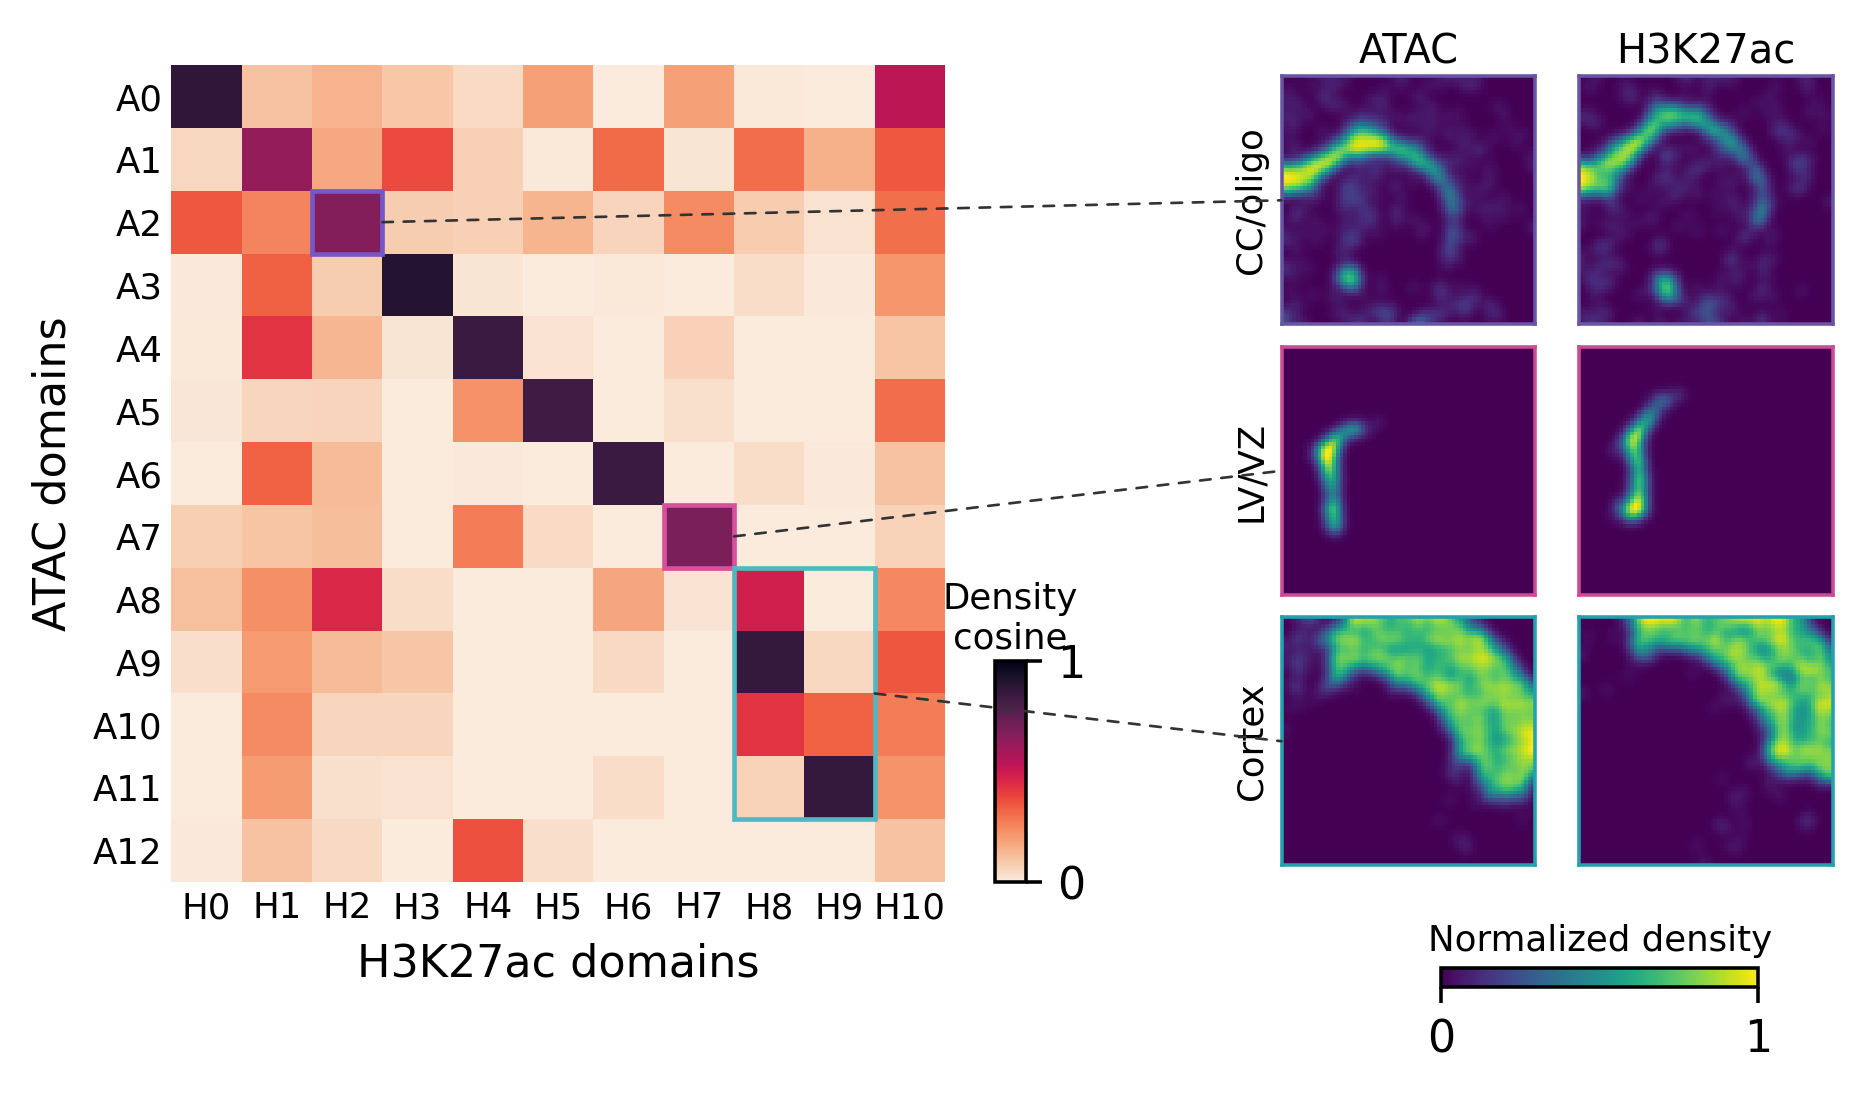

,region,T3 ATAC domains,T4 H3K27ac domains
0,CC/oligo,D2,D4
1,LV/VZ,D11,D10
2,Cortex,"D3, D4, D7, D9","D2, D5"


In [2]:
atac, atac_labels, atac_xy, atac_map, _ = reg.read_run(
    T3_RUN, T3_EMBEDDINGS, evidence["atac_coordinates"], 13, motif=True
)
h3, h3_labels, h3_xy, h3_map, _ = reg.read_run(
    T4_RUN, T4_EMBEDDINGS, evidence["h3_coordinates"], 11, motif=False
)
region_map = pd.DataFrame({
    "region": list(reg.GROUPS),
    "T3 ATAC domains": [", ".join(atac_map.index[atac_map.isin(domains)])
                        for domains in reg.GROUPS_ATAC.values()],
    "T4 H3K27ac domains": [", ".join(h3_map.index[h3_map.isin(domains)])
                           for domains in reg.GROUPS_H3.values()],
})
density = reg.domain_density_cosine(atac_labels, atac_xy, h3_labels, h3_xy)
density_grids = regional_density_grids(atac_labels, atac_xy, h3_labels, h3_xy)
save_panel("d", plot_density_correspondence(density, density_grids))
display(region_map)


## Fig. 4e · Check domain correspondence with paired RNA

Compute a per-gene inside-minus-outside expression effect for each
original domain. Across 1,754 shared highly variable genes, Spearman
correlation compares the domain effect profiles between the two sections.
The 13 × 11 RNA matrix and regional RNA program maps provide a separate
readout of correspondence. The replay uses the prespecified regions
shown in d and e for candidate selection.

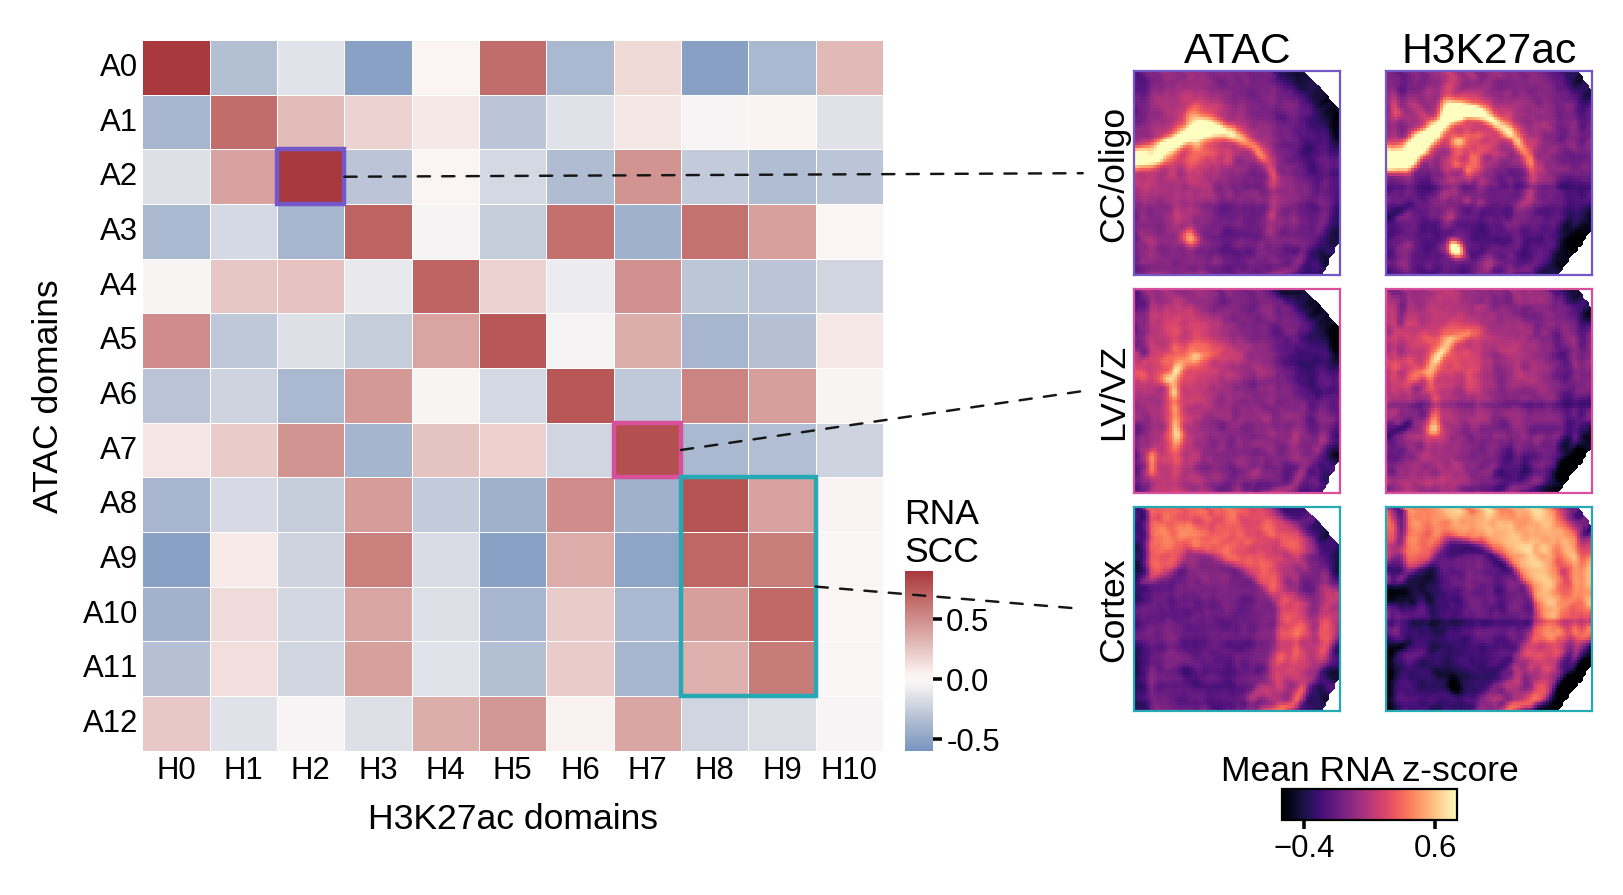

H3K27ac_domain,H0,H1,H2,H3,H4,H5,H6,H7,H8,H9,H10
ATAC_domain,,,,,,,,,,,
A0,0.886,-0.338,-0.136,-0.525,0.016,0.650,-0.373,0.154,-0.534,-0.377,0.296
A1,-0.400,0.651,0.283,0.186,0.087,-0.303,-0.145,0.096,-0.029,0.027,-0.147
A2,-0.159,0.404,0.884,-0.306,0.015,-0.200,-0.364,0.470,-0.270,-0.351,-0.304
A3,-0.372,-0.190,-0.393,0.698,-0.046,-0.266,0.636,-0.419,0.625,0.412,0.011
A4,-0.043,0.236,0.256,-0.107,0.689,0.178,-0.093,0.481,-0.295,-0.302,-0.217
A5,0.496,-0.293,-0.160,-0.264,0.386,0.755,-0.048,0.347,-0.393,-0.335,0.089
A6,-0.312,-0.229,-0.374,0.446,-0.034,-0.197,0.757,-0.280,0.548,0.419,-0.042
A7,0.103,0.214,0.466,-0.401,0.250,0.195,-0.211,0.789,-0.378,-0.346,-0.229
A8,-0.390,-0.189,-0.265,0.431,-0.271,-0.421,0.504,-0.422,0.768,0.407,0.023


In [3]:
atac_rna = load_section_rna(evidence["atac_rna"], atac_labels, atac_xy)
h3_rna = load_section_rna(evidence["h3_rna"], h3_labels, h3_xy)
rna_identity = compute_rna_identity(atac_rna, h3_rna)
save_panel("e", plot_rna_identity(rna_identity))
display(rna_identity["matrix"].round(3))


## Fig. 4f · Intersect regional distal ATAC and H3K27ac candidates

For each assay and region, subtract the mean spot–peak cosine over all
other spots from the mean over the target-region spots. Among positive,
valid, distal, nonblacklisted peaks, take the top 10% (rounded up) in
each assay. The support fraction counts candidate ATAC peaks overlapping
at least one candidate H3K27ac interval by both 50 bp and 10% of the ATAC
peak length. Compute this for all nine pairs. Rank the top 50 positive
ATAC motifs using the same region-versus-rest contrast for the PWM join.


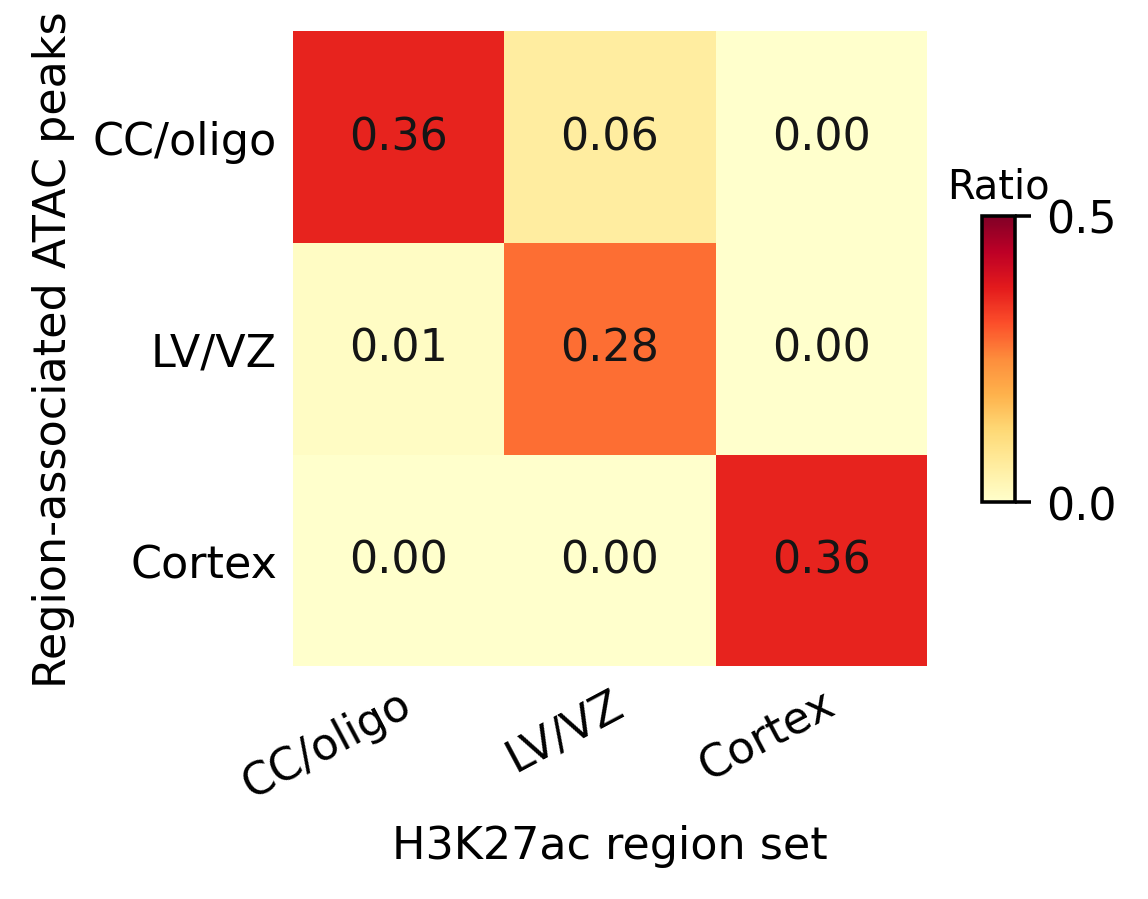

,atac_group,h3_group,n_atac,n_h3,n_supported,support_fraction
0,CC/oligo,CC/oligo,3062,1827,1117,0.364794
1,LV/VZ,LV/VZ,552,945,155,0.280797
2,Cortex,Cortex,4955,3479,1808,0.364884


In [4]:
atac_candidates, motifs = reg.distal_and_motifs(
    atac, atac_labels, reg.GROUPS_ATAC, evidence["atac_annotations"], "enhancer_rank"
)
h3_candidates, _ = reg.distal_and_motifs(
    h3, h3_labels, reg.GROUPS_H3, evidence["h3_annotations"], "h3_rank"
)
support, details = reg.support_tables(atac_candidates, h3_candidates)
save_panel("f", plot_interval_support(support))
display(support.loc[support.is_matched].drop(columns="is_matched").reset_index(drop=True))


## Fig. 4g · Compare regional RNA for the early target sets

Join the ATAC candidates with matched H3K27ac support from f to the
upstream P2G associations (r ≥ 0.2, analytic FDR ≤ 0.1). Deduplicate
targets within each region. For the RNA analysis, use the genes
evaluable in both sections. Standardize each gene's log1p(CP10K)
across spots within each section, average by region and across
sections, and summarize across genes with medians and 95% bootstrap
intervals.


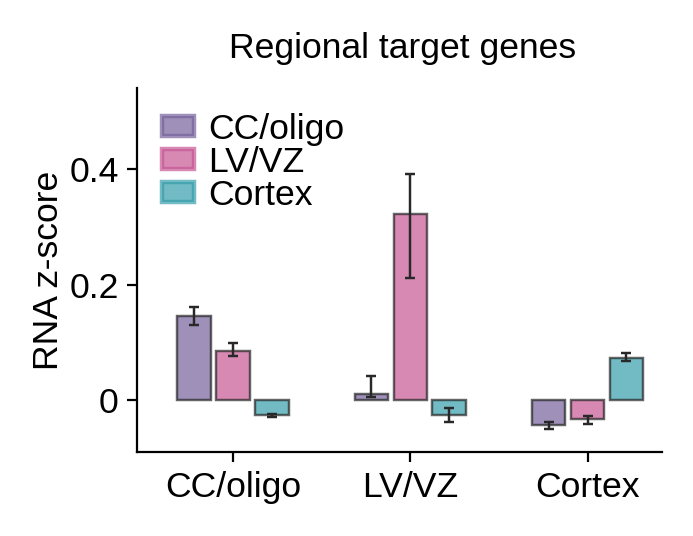

target_set
CC/oligo    589
Cortex      728
LV/VZ        61
Name: Matched targets, dtype: int64

In [5]:
matched_peaks = details.loc[details.is_matched_pair & details.supported, ["atac_group", "peak_id"]]
official_p2g = reg.read_table(evidence["p2g"], usecols=["peak_name", "symbol", "Correlation", "FDR"])
qualifying_p2g = official_p2g.loc[
    official_p2g.Correlation.ge(.2) & official_p2g.FDR.le(.1)
].dropna(subset=["peak_name", "symbol"])
early_targets = matched_peaks.merge(qualifying_p2g, left_on="peak_id", right_on="peak_name")
early_targets = (early_targets.assign(target_upper=early_targets.symbol.str.upper())
                 .rename(columns={"atac_group": "target_set"})[["target_set", "target_upper"]]
                 .drop_duplicates().sort_values(["target_set", "target_upper"]))
rna_values, rna_bars, rna_tests = compute_target_rna(atac_rna, h3_rna, early_targets)
save_panel("g", plot_target_rna(rna_bars))
display(early_targets.groupby("target_set").size().rename("Matched targets"))


## Fig. 4h · Test GO biological-process enrichment

Use the early matched target sets before the RNA evaluability filter and
map them to the GO annotation. The background contains 6,115 annotated
genes from the official P2G universe. One-sided hypergeometric tests
cover 2,117 terms per region, with BH correction across all 6,351 tests.
The panel shows up to three terms per region with q < 0.05 and at least
three hits, ordered by significance, with log₂ fold enrichment.

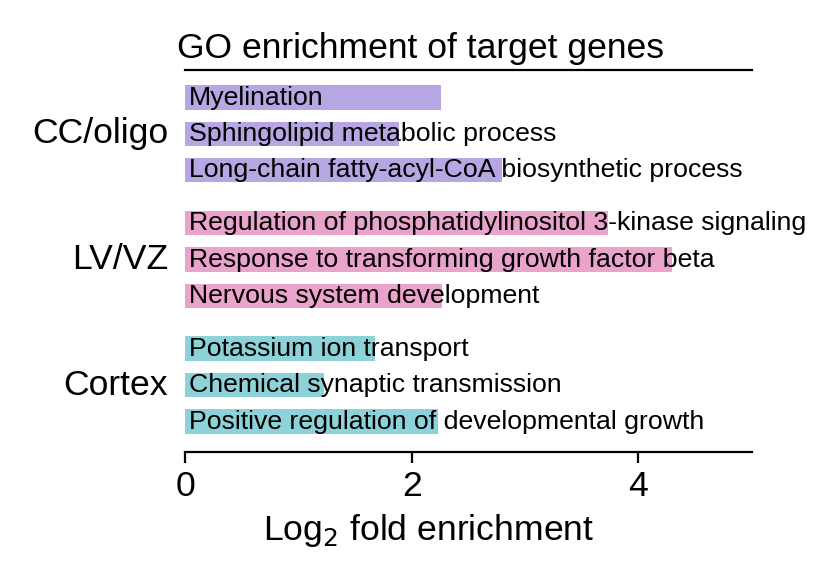

,region,GO_term,log2_fold_enrichment,BH_q_global_6351,target_hits
663,CC/oligo,Myelination (GO:0042552),2.257449,0.025091,10
2022,CC/oligo,Sphingolipid Metabolic Process (GO:0006665),1.886611,0.043405,12
545,CC/oligo,Long-Chain fatty-acyl-CoA Biosynthetic Process...,2.793502,0.049892,6
5611,Cortex,Potassium Ion Transport (GO:0006813),1.674857,0.010886,20
4521,Cortex,Chemical Synaptic Transmission (GO:0007268),1.228234,0.010886,32
5385,Cortex,Positive Regulation Of Developmental Growth (G...,2.227398,0.011184,11
3916,LV/VZ,Regulation Of Phosphatidylinositol 3-Kinase Si...,3.732647,0.033582,5
4093,LV/VZ,Response To Transforming Growth Factor Beta (G...,4.299687,0.039331,4
3020,LV/VZ,Nervous System Development (GO:0007399),2.270304,0.049892,9


In [6]:
go_tests, go_terms = compute_target_go(early_targets, official_p2g.symbol.dropna(), evidence["go_gmt"])
save_panel("h", plot_target_go(go_terms))
display(go_terms.loc[go_terms.displayed_in_main, ["region", "GO_term", "log2_fold_enrichment",
                                                "BH_q_global_6351", "target_hits"]])


## Fig. 4i · Build the complete candidate regulatory network

Return to the matched ATAC peaks in f. Weight the measured H3K27ac
profiles of overlapping raw features by overlap length and retain peaks
with a positive matched-minus-mismatched H3K27ac effect. Use the official
P2G thresholds above and require a positive target RNA effect in both
sections. A contributing motif must be in the top 50 positive regional
motifs and have a PWM hit in the peak. Among a motif's mapped TFs with
positive regional RNA and BH FDR < 0.05, use the strongest RNA effect.

For each region–TF–peak–target key with multiple qualifying motifs, keep
the largest motif–peak cosine. Collapse across the peak dimension to
display TF–target edges while retaining the supporting peaks in the
exported table. The v12 panel displays all 353 CC/oligo edges.
The calculation returns complete edge and triplet tables for all three
regions. Each triplet is a candidate association, and the P2G FDR
describes the peak–gene link.


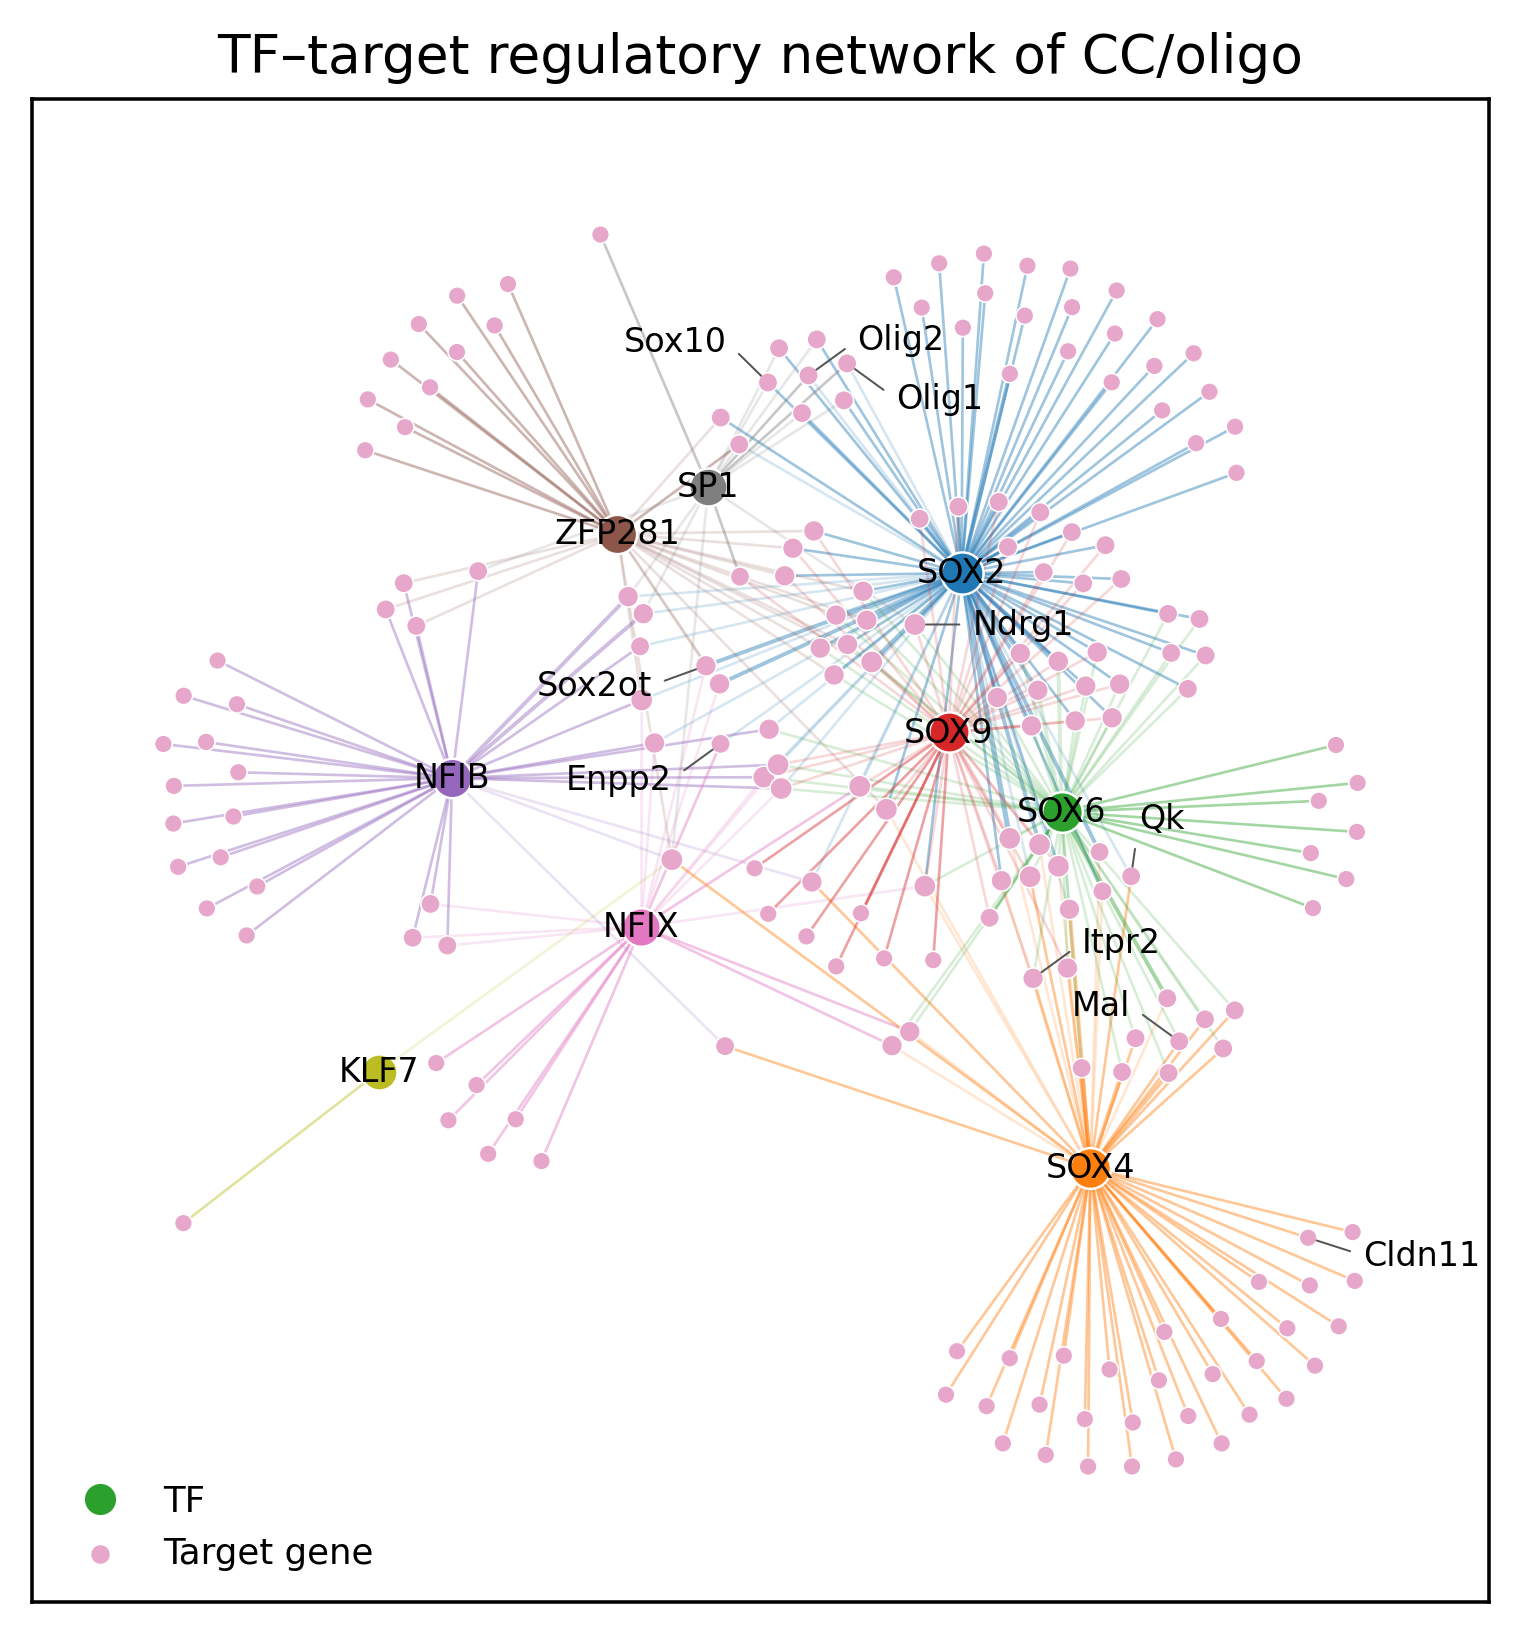

,triplets,TFs,elements,targets,edges
group,,,,,
CC/oligo,375,9,168,194,353
LV/VZ,55,10,21,23,55
Cortex,384,6,169,204,360


In [7]:
matched, raw_h3, p2g = reg.network_evidence(details, h3_labels, evidence)
target_rna = target_rna_effects(rna_identity)
motif_to_tf = reg.read_table(evidence["motif_to_tf"])
tf_tests = compute_tf_rna_tests(atac_rna, motif_to_tf)
triplets = reg.build_triplets(
    matched, raw_h3, motifs, p2g, target_rna, tf_tests, motif_to_tf,
    atac, evidence["pwm"]
)
edges = reg.collapse_edges(triplets)
summary = reg.summarize_network(triplets, edges)
save_panel("i", plot_cc_network(edges))
display(summary)


## Fig. 4j · Inspect the SOX6–Mal locus

Inspect the candidate at ATAC peak chr2:127,627,255–127,628,224,
which overlaps H3K27ac interval chr2:127,626,955–127,627,859.
Read local fragment intervals, normalize each spot's coverage by its
whole-section fragment total, and average across spots within each region. Use the
original peak-to-gene associations, SOX6 PWM, gene model and paired
RNA counts alongside the motif and peak spatial scores calculated
from the saved T3/T4 embeddings.


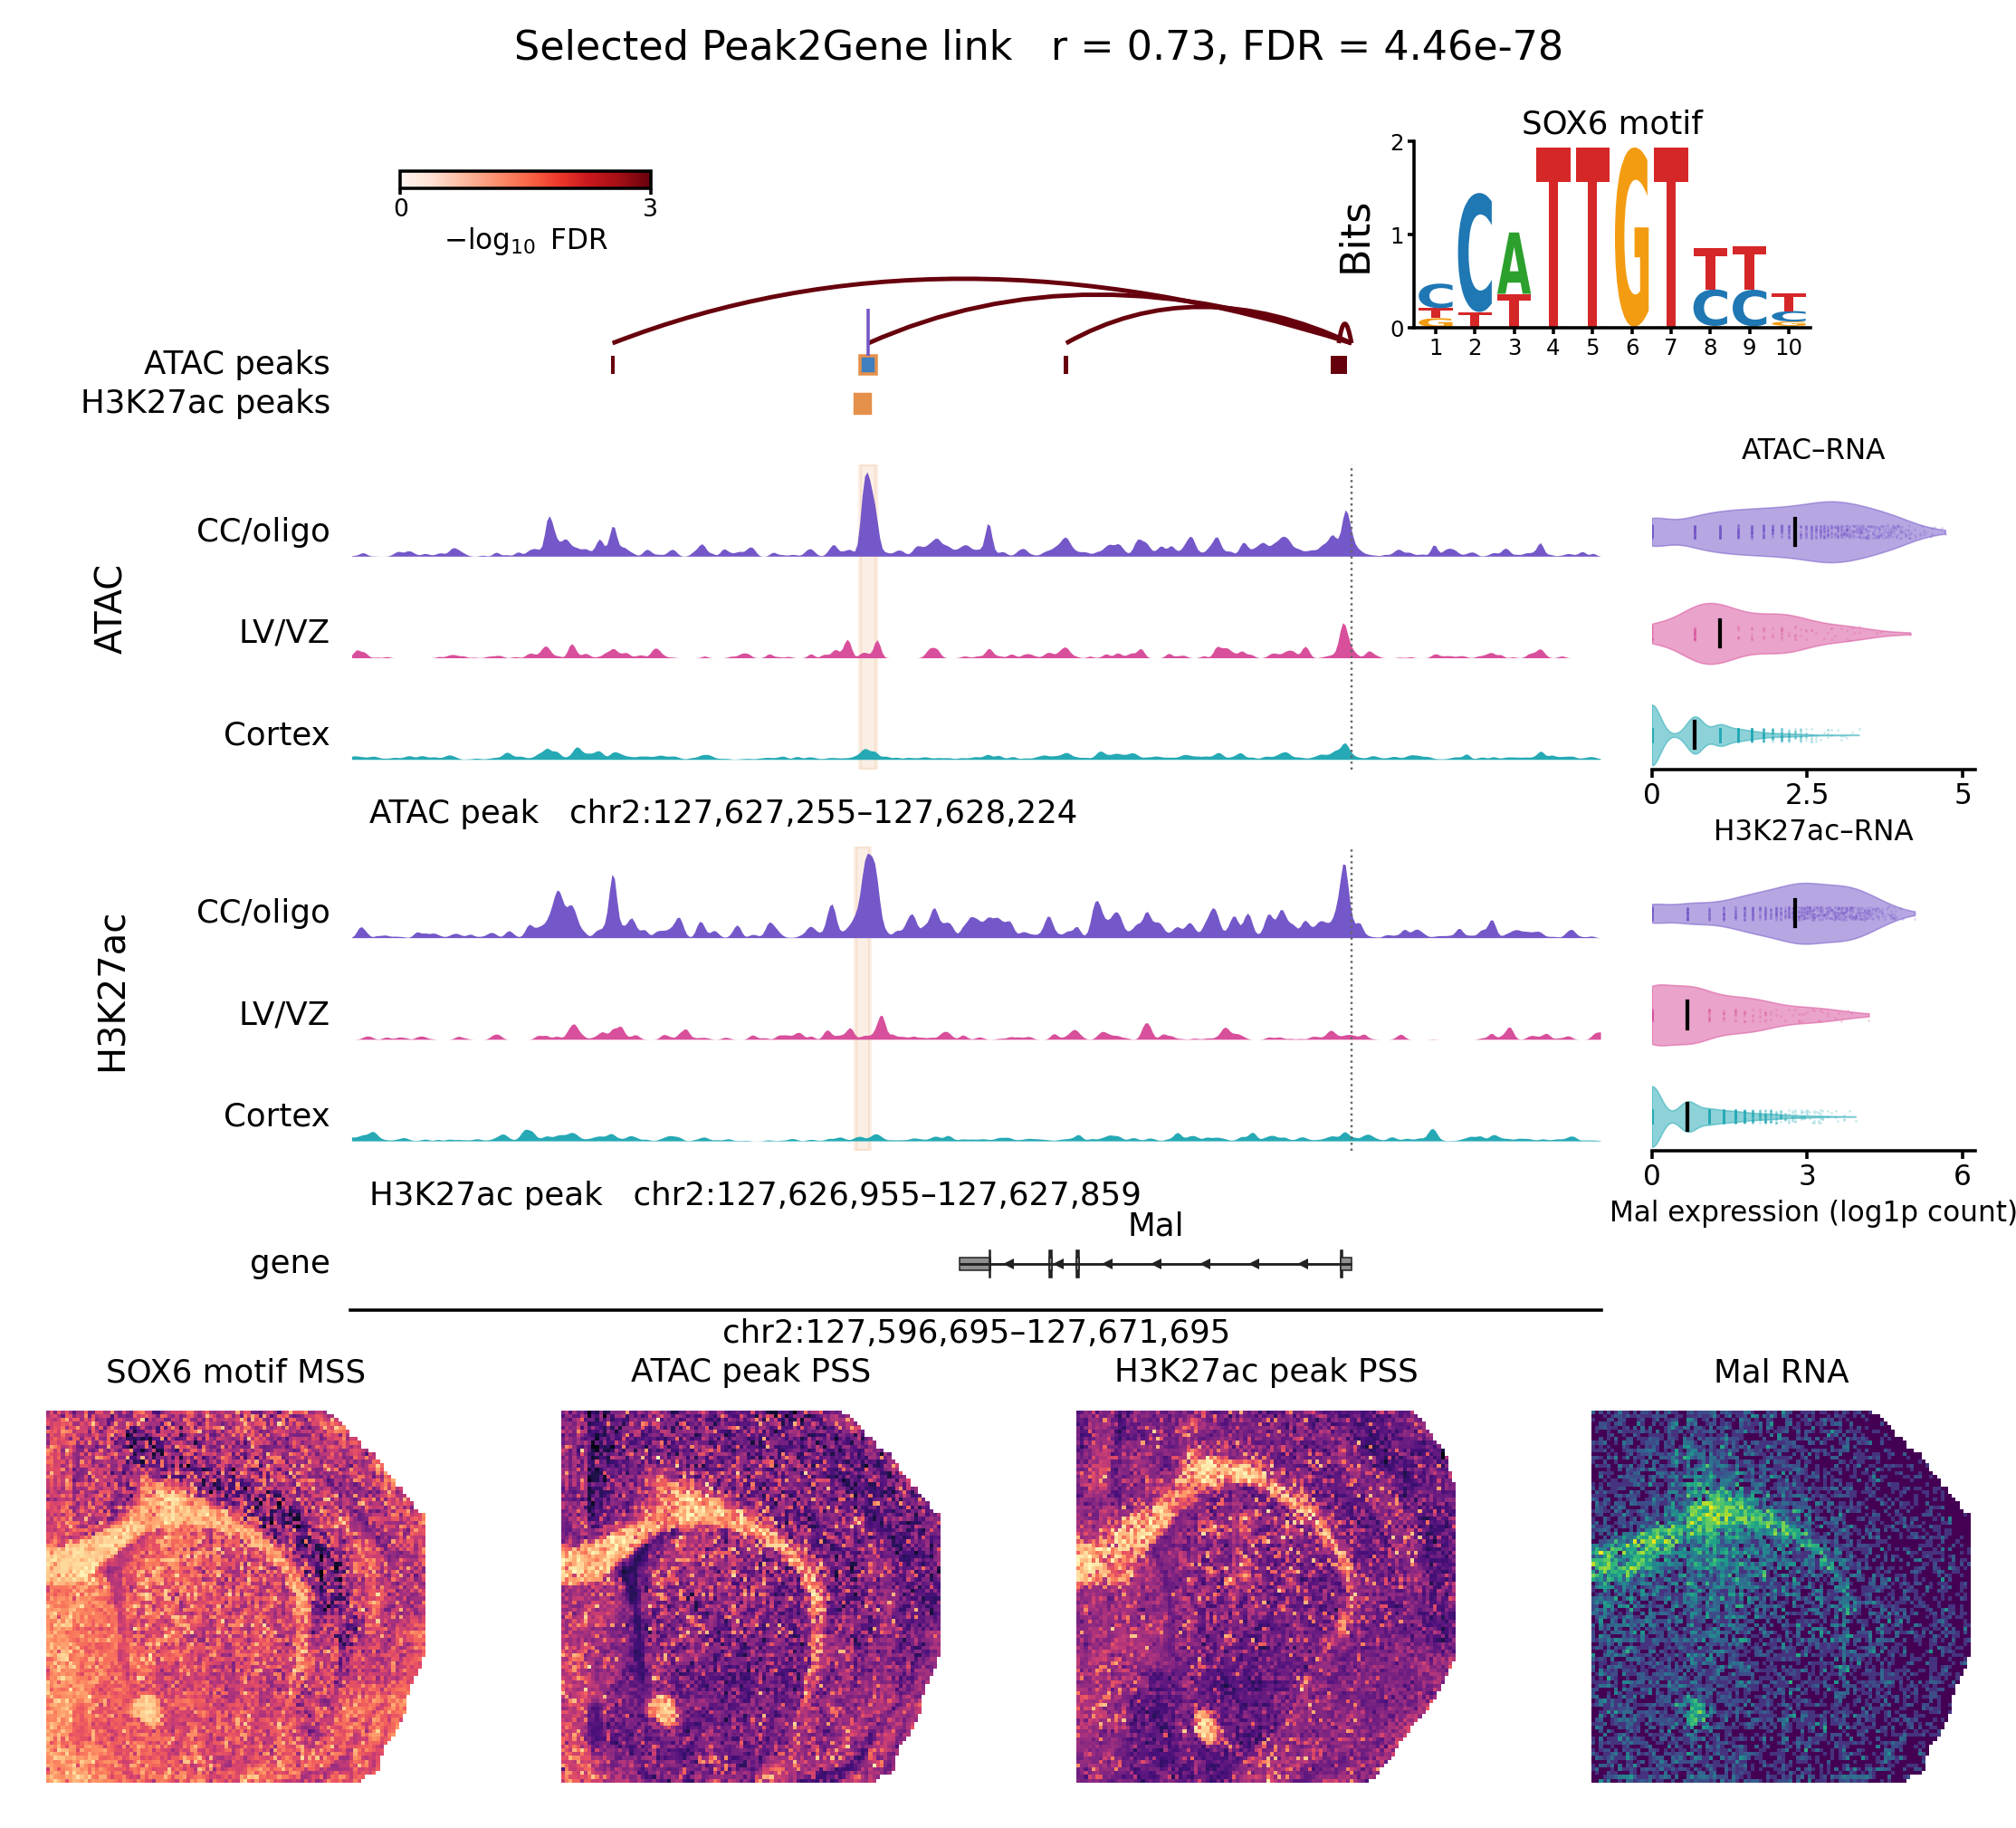

,TF,peak_id,target_gene,motif,overlap_h3_ids,max_overlap_bp,Correlation,FDR
0,Sox6,chr2-127627255-127628224,Mal,Sox6_MA0515_1,chr2-127626955-127627859,604,0.726235,4.460895e-78


In [8]:
case = triplets.loc[
    triplets.group.eq("CC/oligo") & triplets.TF.eq("Sox6") & triplets.target_gene.eq("Mal")
    & triplets.peak_id.eq("chr2-127627255-127628224"),
    ["TF", "peak_id", "target_gene", "motif", "overlap_h3_ids", "max_overlap_bp", "Correlation", "FDR"],
]
locus = compute_locus(atac, atac_labels, atac_xy, h3, h3_labels, h3_xy, evidence)
save_panel("j", plot_locus(locus))
display(case.reset_index(drop=True))


## 2. Save the evidence tables

The same run directory contains the freshly generated PNGs and
editable PDFs. Save the numerical results for reuse or comparison.


In [9]:
tables = {
    "fig4d_density_cosine.tsv": density.reset_index(),
    "fig4e_rna_spearman.tsv": rna_identity["matrix"].reset_index(),
    "atac_candidates.tsv.gz": atac_candidates,
    "h3_candidates.tsv.gz": h3_candidates,
    "interval_support.tsv": support,
    "interval_support_by_peak.tsv.gz": details,
    "matched_target_membership.tsv": early_targets,
    "target_rna_values.tsv.gz": rna_values,
    "target_rna_bars.tsv": rna_bars,
    "target_rna_tests.tsv": rna_tests,
    "go_tests.tsv.gz": go_tests,
    "go_summary.tsv": go_terms,
    "raw_h3_effects.tsv.gz": raw_h3,
    "tf_rna_tests.tsv": tf_tests,
    "triplets.tsv.gz": triplets,
    "edges.tsv": edges,
    "network_counts.tsv": summary.reset_index(),
    "sox6_mal_triplet.tsv": case,
    "sox6_mal_fragment_tracks.tsv": locus["tracks"],
    "sox6_mal_rna_spots.tsv.gz": locus["rna_points"],
    "sox6_mal_spatial_values.tsv.gz": locus["maps"],
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / name, sep="\t", index=False)
print(f"Saved {len(tables)} evidence tables and seven PNG/PDF pairs.")


Saved 21 evidence tables and seven PNG/PDF pairs.
